# Lung Cancer Prediction

Author: Joaquín García Pozo

Dataset: https://www.kaggle.com/datasets/shantanugarg274/lung-cancer-prediction-dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, 
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    confusion_matrix, 
    classification_report, 
    roc_curve, 
    auc
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, 
    StackingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from tabulate import tabulate
import math

# 1. Loading the dataset

In [2]:
df = pd.read_csv("lung-cancer-dataset.csv")

# 2. Exploratory Data Analysis

## 2.1 General description of the dataset

In [3]:
print(f"Dataset dimensions: {df.shape[0]} rows and {df.shape[1]} columns\n")

Dataset dimensions: 5000 rows and 18 columns



In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
AGE                         int64
GENDER                      int64
SMOKING                     int64
FINGER_DISCOLORATION        int64
MENTAL_STRESS               int64
EXPOSURE_TO_POLLUTION       int64
LONG_TERM_ILLNESS           int64
ENERGY_LEVEL              float64
IMMUNE_WEAKNESS             int64
BREATHING_ISSUE             int64
ALCOHOL_CONSUMPTION         int64
THROAT_DISCOMFORT           int64
OXYGEN_SATURATION         float64
CHEST_TIGHTNESS             int64
FAMILY_HISTORY              int64
SMOKING_FAMILY_HISTORY      int64
STRESS_IMMUNE               int64
PULMONARY_DISEASE          object
dtype: object


In [5]:
print("\nFirst rows of the dataset:")
print(df.head())


First rows of the dataset:
   AGE  GENDER  SMOKING  FINGER_DISCOLORATION  MENTAL_STRESS  \
0   68       1        1                     1              1   
1   81       1        1                     0              0   
2   58       1        1                     0              0   
3   44       0        1                     0              1   
4   72       0        1                     1              1   

   EXPOSURE_TO_POLLUTION  LONG_TERM_ILLNESS  ENERGY_LEVEL  IMMUNE_WEAKNESS  \
0                      1                  0     57.831178                0   
1                      1                  1     47.694835                1   
2                      0                  0     59.577435                0   
3                      1                  0     59.785767                0   
4                      1                  1     59.733941                0   

   BREATHING_ISSUE  ALCOHOL_CONSUMPTION  THROAT_DISCOMFORT  OXYGEN_SATURATION  \
0                0                   

In [6]:
print("\nUnique values per column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")


Unique values per column:
AGE: 55 unique values
GENDER: 2 unique values
SMOKING: 2 unique values
FINGER_DISCOLORATION: 2 unique values
MENTAL_STRESS: 2 unique values
EXPOSURE_TO_POLLUTION: 2 unique values
LONG_TERM_ILLNESS: 2 unique values
ENERGY_LEVEL: 5000 unique values
IMMUNE_WEAKNESS: 2 unique values
BREATHING_ISSUE: 2 unique values
ALCOHOL_CONSUMPTION: 2 unique values
THROAT_DISCOMFORT: 2 unique values
OXYGEN_SATURATION: 5000 unique values
CHEST_TIGHTNESS: 2 unique values
FAMILY_HISTORY: 2 unique values
SMOKING_FAMILY_HISTORY: 2 unique values
STRESS_IMMUNE: 2 unique values
PULMONARY_DISEASE: 2 unique values


## 2.2 Univariate Analysis

In [7]:
# Numerical variables (float, int)
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Categorical variables (object, binary)
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical variables:", num_cols)
print("Categorical variables:", cat_cols)

Numerical variables: ['AGE', 'GENDER', 'SMOKING', 'FINGER_DISCOLORATION', 'MENTAL_STRESS', 'EXPOSURE_TO_POLLUTION', 'LONG_TERM_ILLNESS', 'ENERGY_LEVEL', 'IMMUNE_WEAKNESS', 'BREATHING_ISSUE', 'ALCOHOL_CONSUMPTION', 'THROAT_DISCOMFORT', 'OXYGEN_SATURATION', 'CHEST_TIGHTNESS', 'FAMILY_HISTORY', 'SMOKING_FAMILY_HISTORY', 'STRESS_IMMUNE']
Categorical variables: ['PULMONARY_DISEASE']


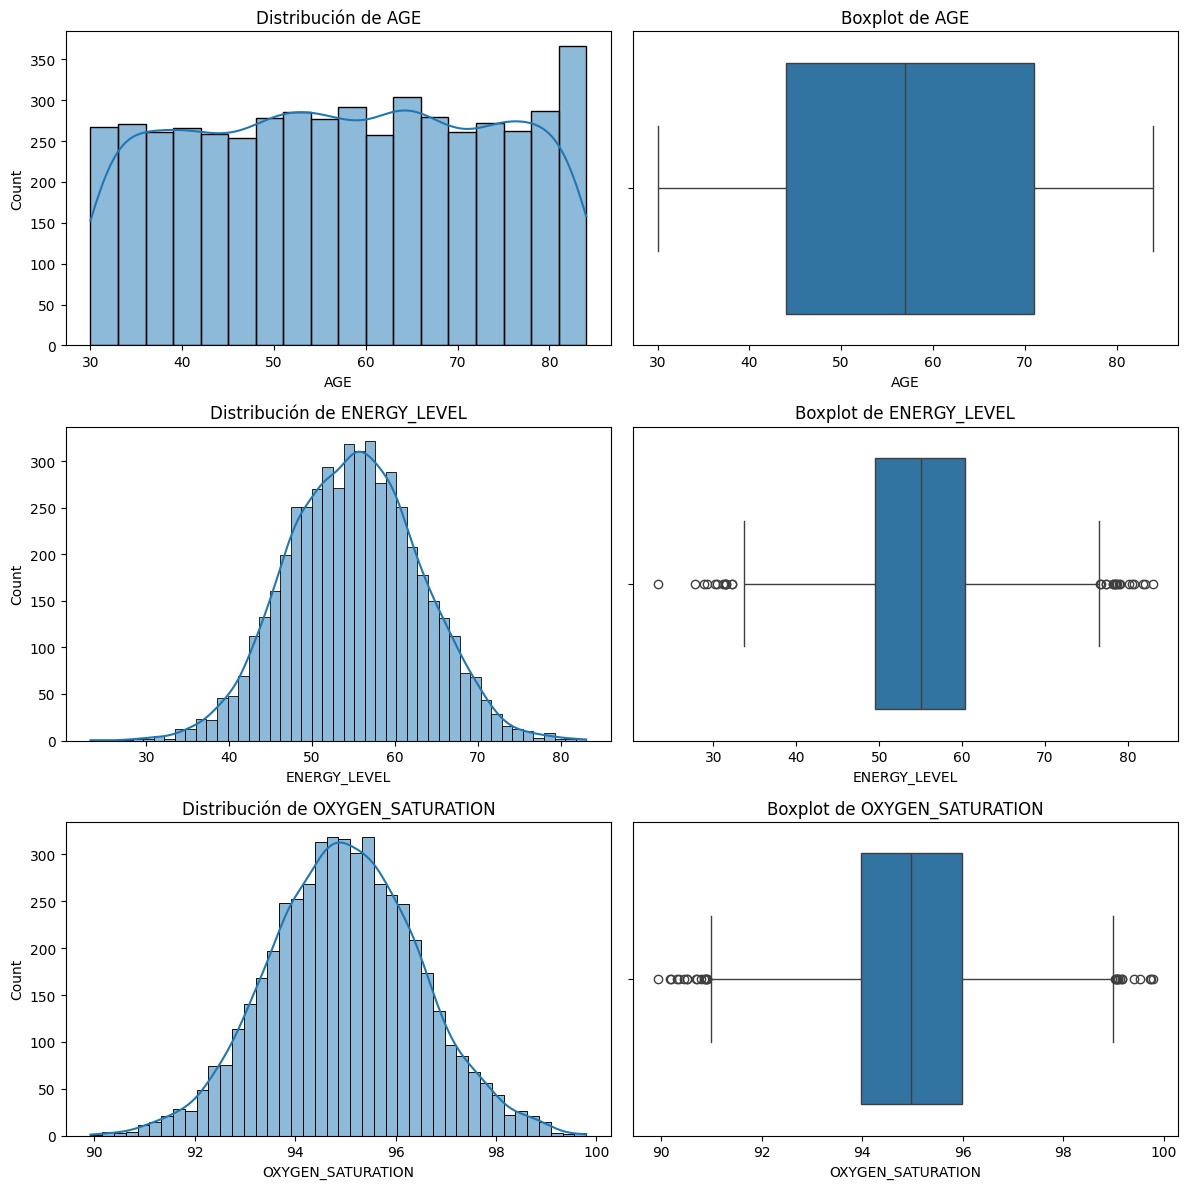

In [8]:
num_vars = ['AGE', 'ENERGY_LEVEL', 'OXYGEN_SATURATION']

cols = 2
rows = len(num_vars)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

for i, col in enumerate(num_vars):
    # Histogram
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribution of {col}')

    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

The plots show the frequency distribution of the numerical variables using histograms with a density curve (left) and the presence of outliers using boxplots (right). The variable AGE has a relatively uniform distribution, which indicates that the samples cover a wide age range. On the other hand, ENERGY_LEVEL and OXYGEN_SATURATION show approximately normal distributions centered around their means. Normal values for a healthy patient are 55-70 for ENERGY_LEVEL and 95-100 for OXYGEN_SATURATION.

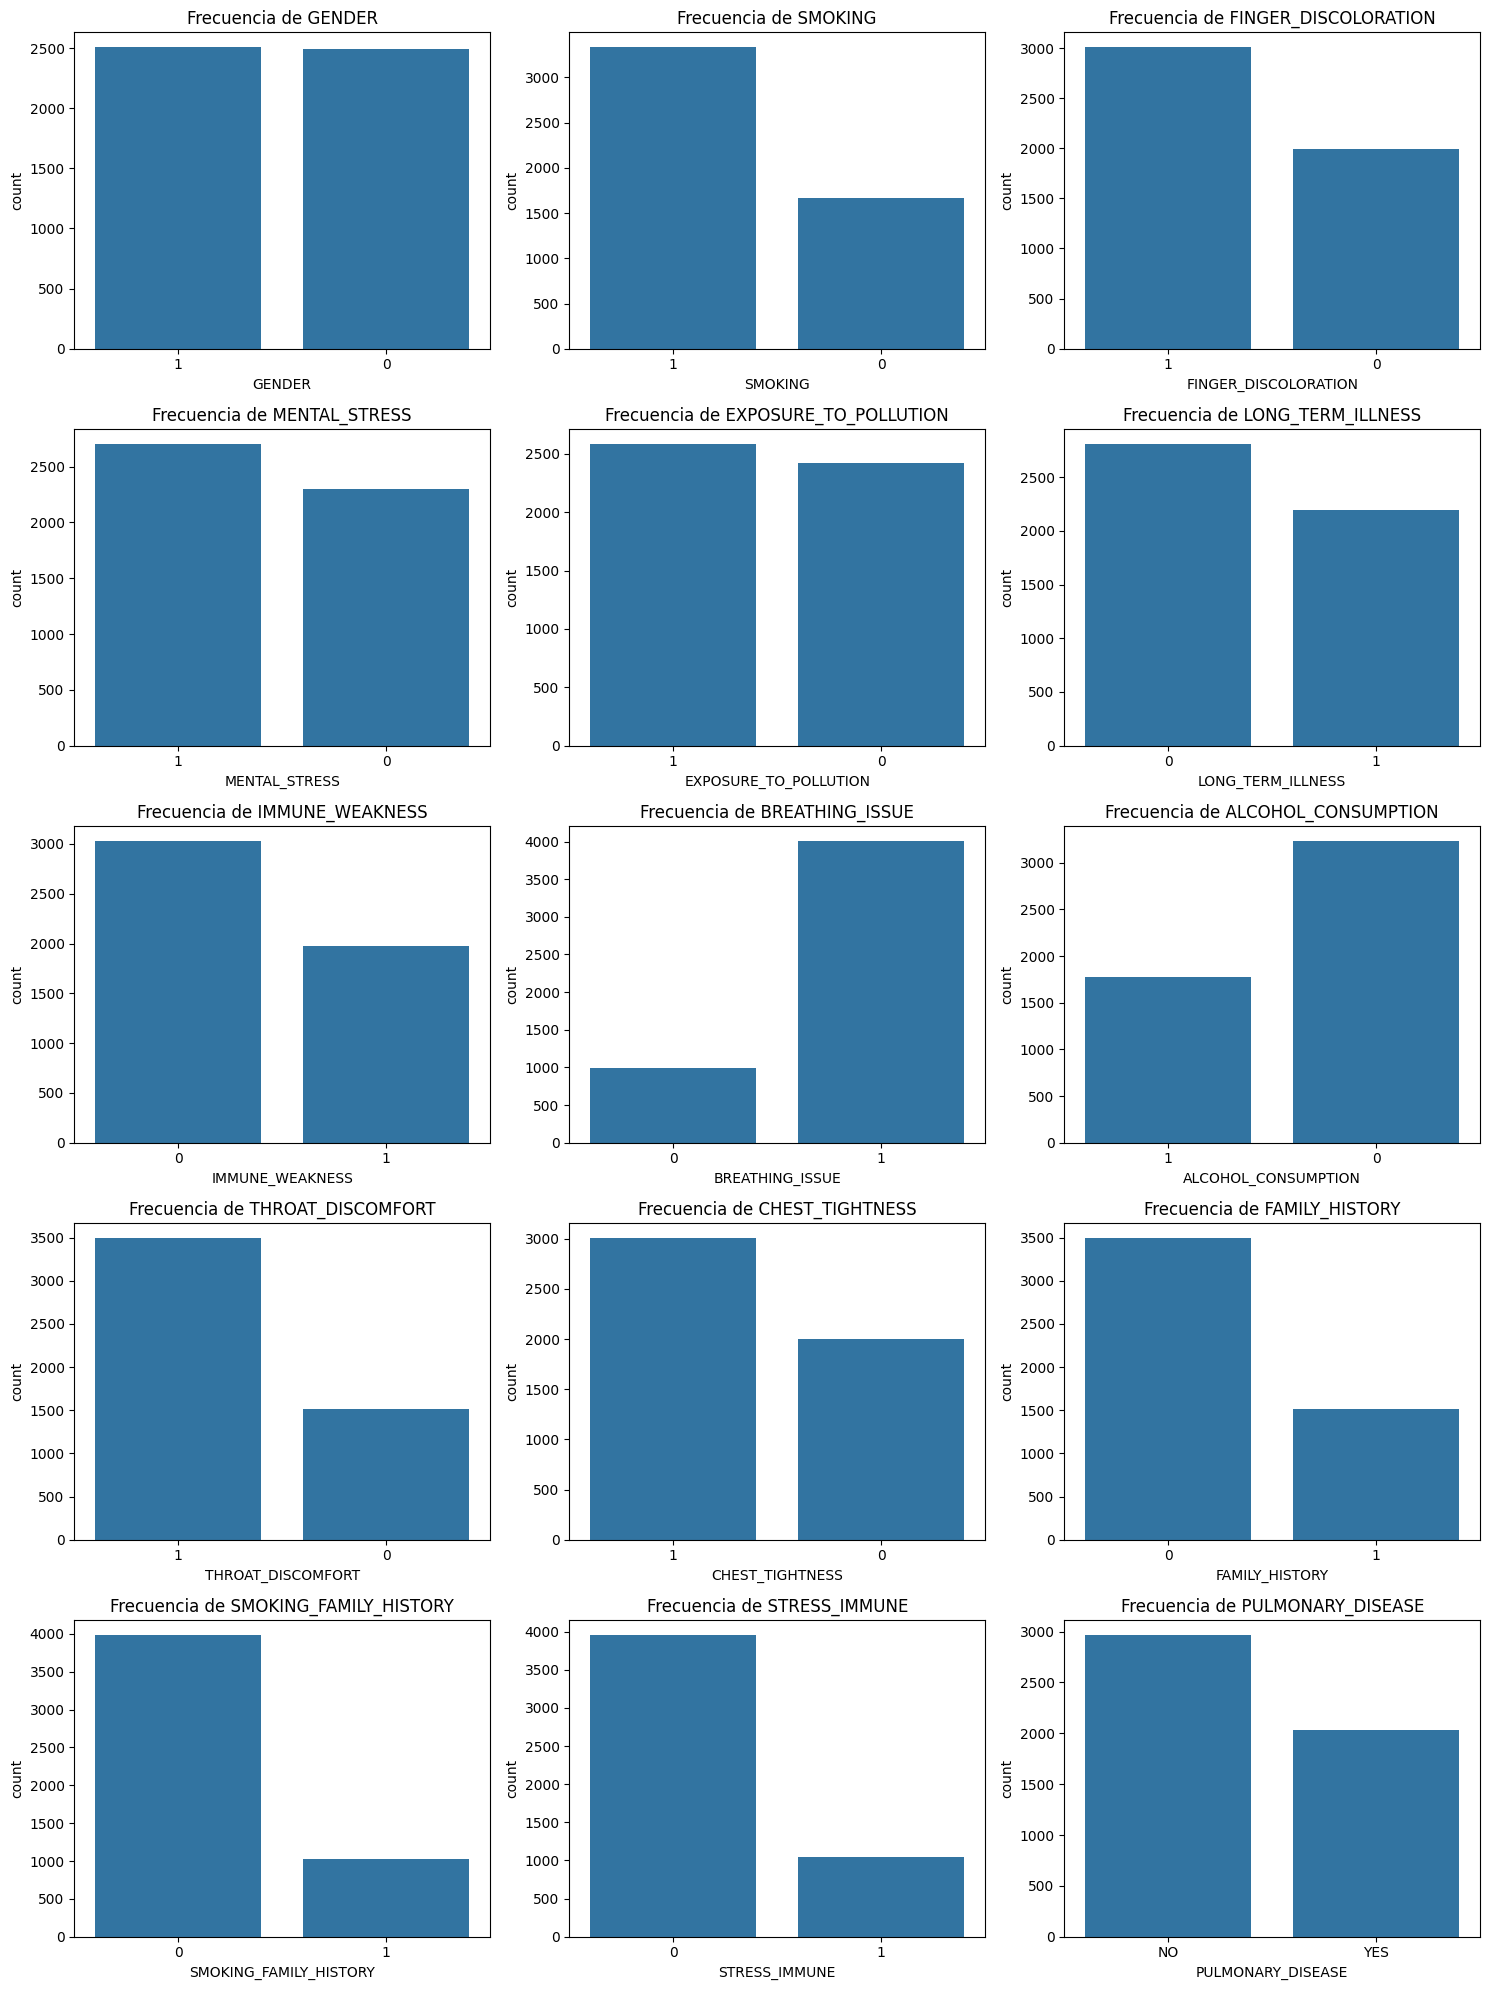

In [9]:
cat_vars = [
    'GENDER', 'SMOKING', 'FINGER_DISCOLORATION', 'MENTAL_STRESS', 'EXPOSURE_TO_POLLUTION',
    'LONG_TERM_ILLNESS', 'IMMUNE_WEAKNESS', 'BREATHING_ISSUE', 'ALCOHOL_CONSUMPTION',
    'THROAT_DISCOMFORT', 'CHEST_TIGHTNESS', 'FAMILY_HISTORY', 'SMOKING_FAMILY_HISTORY',
    'STRESS_IMMUNE', 'PULMONARY_DISEASE'
]

df[cat_vars] = df[cat_vars].astype(str)

cols = 3
rows = math.ceil(len(cat_vars) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_vars):
    sns.countplot(x=col, data=df, ax=axes[i])
    axes[i].set_title(f'Frequency of {col}')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
print("Descriptive statistics of numerical variables:")
print(tabulate(df[num_cols].describe().T.reset_index().rename(columns={'index': 'Variable'}), headers='keys', tablefmt='pretty', showindex=False, floatfmt=".2f"))

Descriptive statistics of numerical variables:
+-------------------+--------+-------------------+--------------------+--------------------+-------------------+-------------------+-------------------+-------------------+
|     Variable      | count  |       mean        |        std         |        min         |        25%        |        50%        |        75%        |        max        |
+-------------------+--------+-------------------+--------------------+--------------------+-------------------+-------------------+-------------------+-------------------+
|        AGE        | 5000.0 |      57.2228      | 15.799224134641907 |        30.0        |       44.0        |       57.0        |       71.0        |       84.0        |
|   ENERGY_LEVEL    | 5000.0 | 55.03204320599922 | 7.9130833495360084 | 23.258308443247664 |  49.440685162634  | 55.05042116788795 | 60.32331992351811 | 83.04697122835933 |
| OXYGEN_SATURATION | 5000.0 | 94.99102906440955 | 1.4810480564997697 | 89.9231326163355

In [11]:
print("\nMode of variables:")
for col in num_cols:
    print(f"{col}: {df[col].mode()[0]}")


Mode of variables:
AGE: 64
GENDER: 1
SMOKING: 1
FINGER_DISCOLORATION: 1
MENTAL_STRESS: 1
EXPOSURE_TO_POLLUTION: 1
LONG_TERM_ILLNESS: 0
ENERGY_LEVEL: 23.258308443247664
IMMUNE_WEAKNESS: 0
BREATHING_ISSUE: 1
ALCOHOL_CONSUMPTION: 0
THROAT_DISCOMFORT: 1
OXYGEN_SATURATION: 89.92313261633554
CHEST_TIGHTNESS: 1
FAMILY_HISTORY: 0
SMOKING_FAMILY_HISTORY: 0
STRESS_IMMUNE: 0


The mode corresponds to a 64-year-old patient (AGE=64), male (GENDER=1), an active smoker (SMOKING=1) with finger discoloration (FINGER_DISCOLORATION=1), which may indicate prolonged exposure to tobacco. The patient has mental stress (MENTAL_STRESS=1) and exposure to pollution (EXPOSURE_TO_POLLUTION=1), but has no long-term chronic illnesses (LONG_TERM_ILLNESS=0) and no immune weakness (IMMUNE_WEAKNESS=0). Their energy level is low (ENERGY_LEVEL=23.26) and they have breathing problems (BREATHING_ISSUE=1), throat discomfort (THROAT_DISCOMFORT=1) and chest tightness (CHEST_TIGHTNESS=1). Such a low energy level suggests the patient may suffer from chronic fatigue. They do not consume alcohol (ALCOHOL_CONSUMPTION=0), have no family history of lung disease or smoking (FAMILY_HISTORY=0, SMOKING_FAMILY_HISTORY=0), and show no stress-related immunosuppression (STRESS_IMMUNE=0). Their oxygen saturation is low (OXYGEN_SATURATION=89.92), indicating possible respiratory insufficiency.

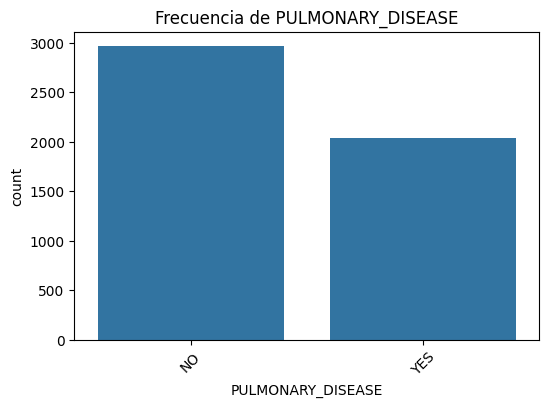


Value counts in PULMONARY_DISEASE:
PULMONARY_DISEASE
NO     59.26
YES    40.74
Name: proportion, dtype: float64


In [12]:
for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Frequency of {col}')
    plt.xticks(rotation=45)
    plt.show()

    print(f"\nValue counts in {col}:")
    print(df[col].value_counts(normalize=True) * 100)

The plots show the frequency distribution of each categorical variable in the dataset, including the target variable PULMONARY_DISEASE. Most variables show some imbalance between their categories, which is especially noticeable in variables such as BREATHING_ISSUE, SMOKING_FAMILY_HISTORY and STRESS_IMMUNE, where most cases belong to category 1 (presence of the characteristic). In other variables, such as GENDER and EXPOSURE_TO_POLLUTION, the distribution is more balanced. For the target variable PULMONARY_DISEASE, there are more negative (NO) than positive (YES) cases. The proportion is 59.26% negative cases versus 40.74% positive cases.

## 2.3 Data quality

In [13]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_data = pd.DataFrame({
    'Null values': missing_count,
    'Percentage (%)': missing_percent
}).sort_values(by='Null values', ascending=False)

print("Null values per column:")
print(missing_data)

Null values per column:
                        Null values  Percentage (%)
AGE                                 0             0.0
GENDER                              0             0.0
STRESS_IMMUNE                       0             0.0
SMOKING_FAMILY_HISTORY              0             0.0
FAMILY_HISTORY                      0             0.0
CHEST_TIGHTNESS                     0             0.0
OXYGEN_SATURATION                   0             0.0
THROAT_DISCOMFORT                   0             0.0
ALCOHOL_CONSUMPTION                 0             0.0
BREATHING_ISSUE                     0             0.0
IMMUNE_WEAKNESS                     0             0.0
ENERGY_LEVEL                        0             0.0
LONG_TERM_ILLNESS                   0             0.0
EXPOSURE_TO_POLLUTION               0             0.0
MENTAL_STRESS                       0             0.0
FINGER_DISCOLORATION                0             0.0
SMOKING                             0             0.0
PULMON

In [14]:
# Check for exact duplicates
duplicados = df.duplicated().sum()
print(f"\nDuplicate rows: {duplicados}")


Duplicate rows: 0


In [15]:
for col in cat_cols:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in PULMONARY_DISEASE:
['NO' 'YES']


Regarding data quality, the dataset has no null values in any column. There are also no duplicate rows. The unique values of the target variable are ['NO' 'YES'].

## 2.4 Bivariate Analysis

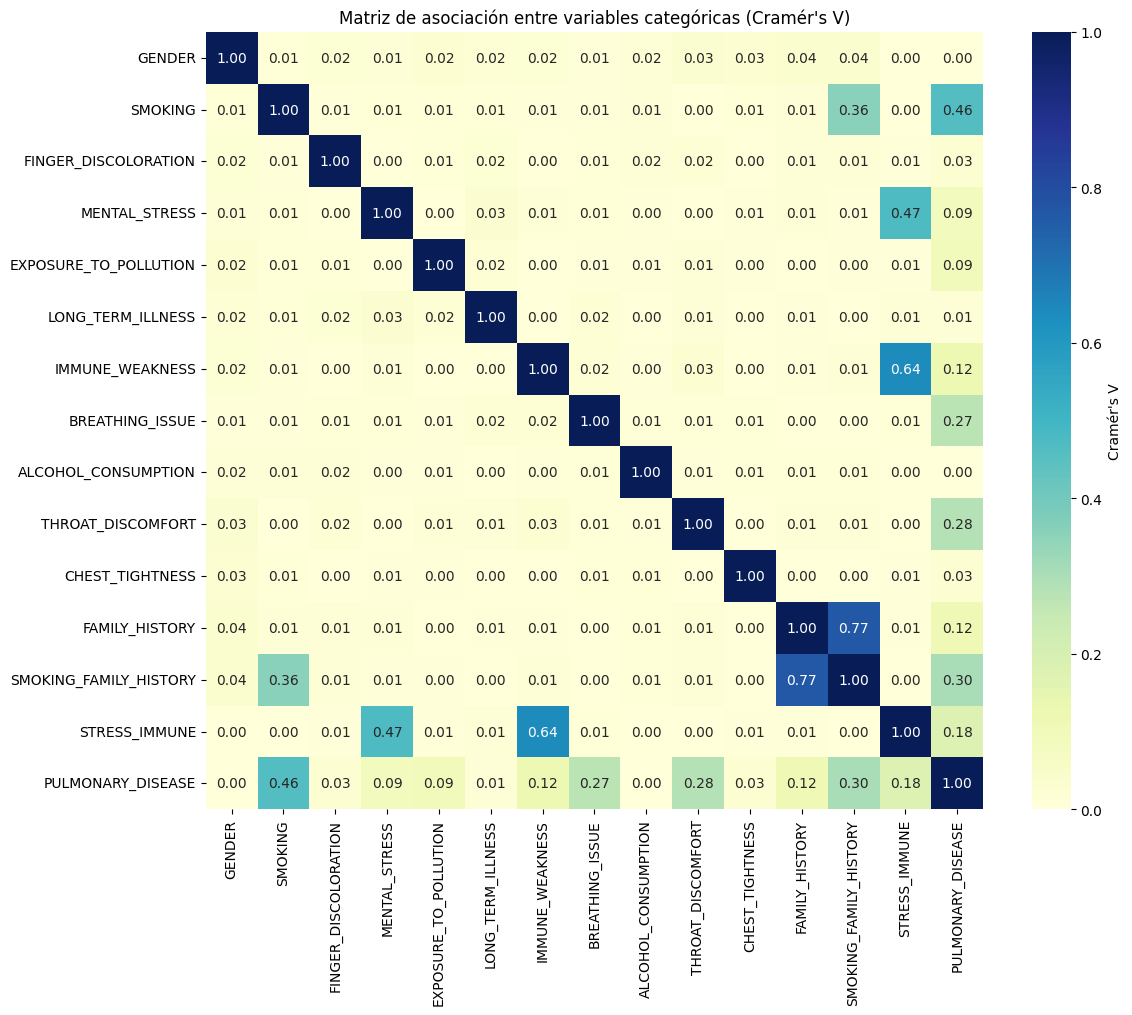

In [51]:
def cramers_v(confusion_matrix):
    if confusion_matrix.shape[0] < 2 or confusion_matrix.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.values.sum()  
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return float(np.sqrt(phi2 / min(k - 1, r - 1)))  


cat_vars = [
    'GENDER', 'SMOKING', 'FINGER_DISCOLORATION', 'MENTAL_STRESS', 'EXPOSURE_TO_POLLUTION',
    'LONG_TERM_ILLNESS', 'IMMUNE_WEAKNESS', 'BREATHING_ISSUE', 'ALCOHOL_CONSUMPTION',
    'THROAT_DISCOMFORT', 'CHEST_TIGHTNESS', 'FAMILY_HISTORY', 'SMOKING_FAMILY_HISTORY',
    'STRESS_IMMUNE', 'PULMONARY_DISEASE'
]

df[cat_vars] = df[cat_vars].astype(str)

cramers_results = pd.DataFrame(np.zeros((len(cat_vars), len(cat_vars))), columns=cat_vars, index=cat_vars)

for var1 in cat_vars:
    for var2 in cat_vars:
        if var1 == var2:
            cramers_results.at[var1, var2] = 1.0
        else:
            confusion_matrix = pd.crosstab(df[var1], df[var2])
            if confusion_matrix.shape[0] < 2 or confusion_matrix.shape[1] < 2:
                cramers_results.at[var1, var2] = np.nan
            else:
                cramers_results.at[var1, var2] = cramers_v(confusion_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cramers_results, 
    annot=True,                  
    fmt=".2f",                   
    cmap="YlGnBu", 
    square=True, 
    cbar_kws={"label": "Cramér's V"}
)
plt.title("Association matrix between categorical variables (Cramér's V)")
plt.tight_layout()
plt.show()

Most correlations are very low (close to 0), which indicates that the variables are largely independent of each other. However, some moderate correlations stand out: FAMILY_HISTORY and SMOKING_FAMILY_HISTORY (0.77); IMMUNE_WEAKNESS and STRESS_IMMUNE (0.64); SMOKING and SMOKING_FAMILY_HISTORY (0.36); and MENTAL_STRESS and STRESS_IMMUNE (0.48).

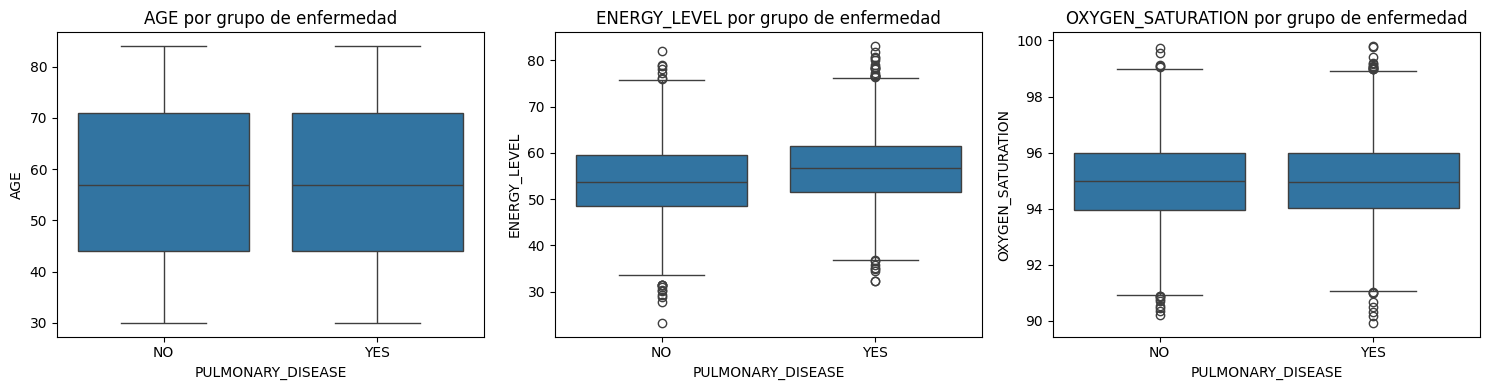

In [17]:
num_vars = ['AGE', 'ENERGY_LEVEL', 'OXYGEN_SATURATION']

cols = 3
rows = math.ceil(len(num_vars) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_vars):
    sns.boxplot(x='PULMONARY_DISEASE', y=col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} by disease group')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

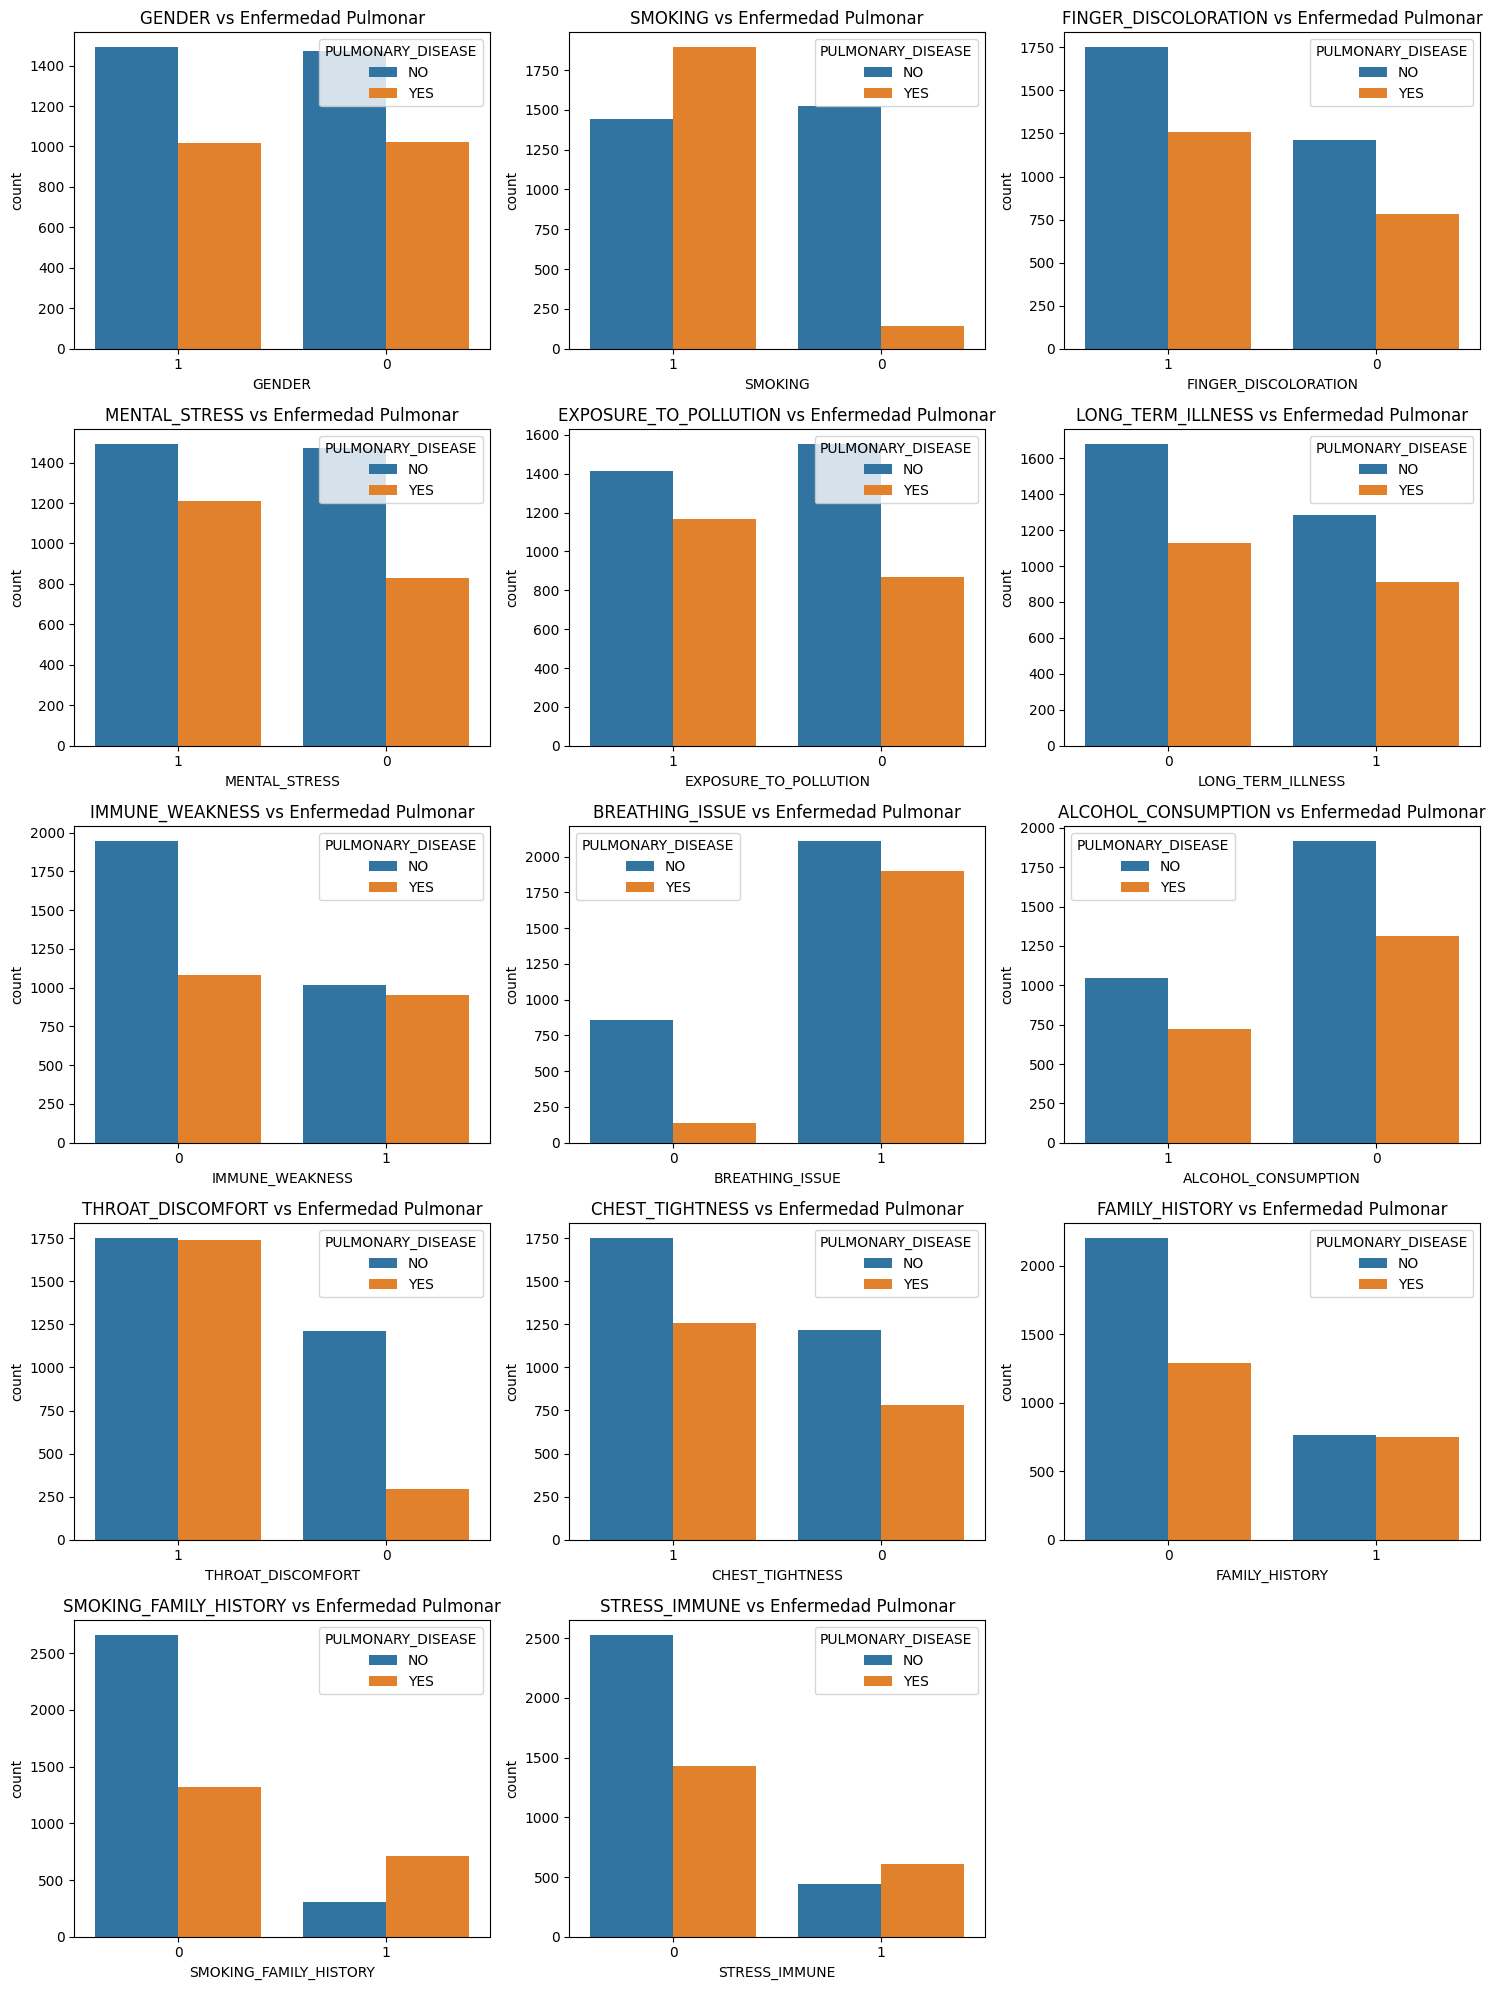

In [ ]:
cat_vars = [
    'GENDER', 'SMOKING', 'FINGER_DISCOLORATION', 'MENTAL_STRESS', 'EXPOSURE_TO_POLLUTION',
    'LONG_TERM_ILLNESS', 'IMMUNE_WEAKNESS', 'BREATHING_ISSUE', 'ALCOHOL_CONSUMPTION',
    'THROAT_DISCOMFORT', 'CHEST_TIGHTNESS', 'FAMILY_HISTORY', 'SMOKING_FAMILY_HISTORY',
    'STRESS_IMMUNE'
]

df[cat_vars + ['PULMONARY_DISEASE']] = df[cat_vars + ['PULMONARY_DISEASE']].astype(str)

cols = 3
rows = math.ceil(len(cat_vars) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_vars):
    sns.countplot(x=col, hue='PULMONARY_DISEASE', data=df, ax=axes[i])
    axes[i].set_title(f'{col} vs Pulmonary Disease')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The analysis reveals that variables such as SMOKING, FINGER_DISCOLORATION, MENTAL_STRESS, EXPOSURE_TO_POLLUTION, BREATHING_ISSUE, THROAT_DISCOMFORT and CHEST_TIGHTNESS show a marked difference between healthy and sick patients. This indicates a strong association with the disease. On the other hand, some variables such as ALCOHOL_CONSUMPTION, FAMILY_HISTORY, SMOKING_FAMILY_HISTORY and IMMUNE_WEAKNESS are balanced between groups, so no high predictive relevance can be identified for them.

After the initial exploratory analysis, some categorical variables potentially associated with the presence of pulmonary disease were identified. To study these relationships in more detail, heatmaps are analyzed below that allow visual association patterns to be observed between these variables and the target variable. These variables are SMOKING, STRESS_IMMUNE, FAMILY_HISTORY and SMOKING_FAMILY_HISTORY.

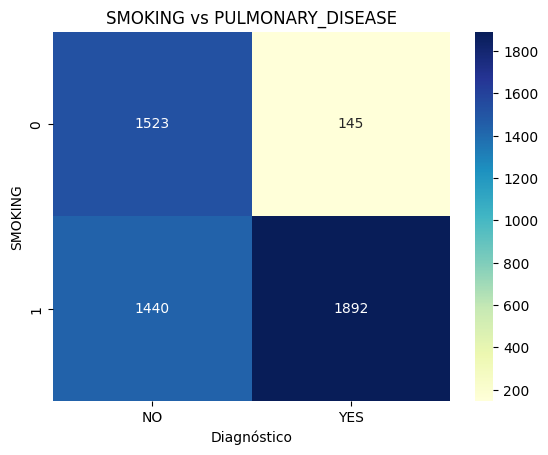

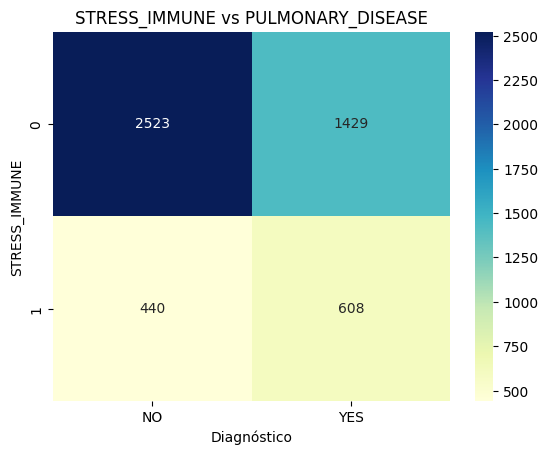

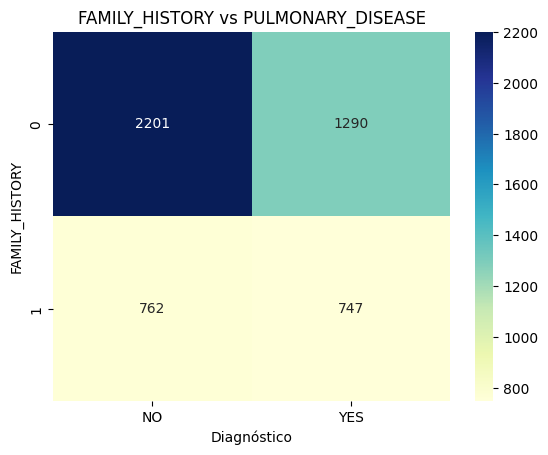

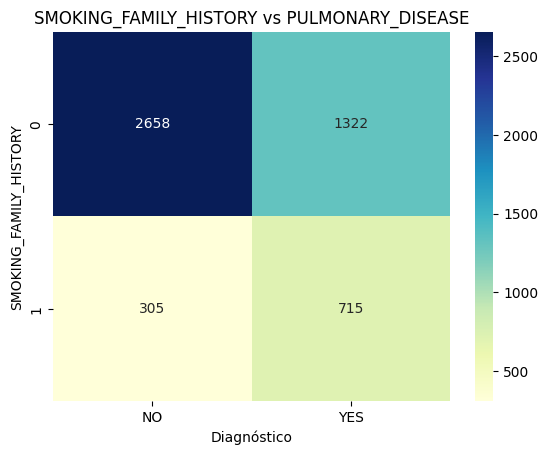

In [19]:
cat_pairs = ['SMOKING', 'STRESS_IMMUNE', 'FAMILY_HISTORY', 'SMOKING_FAMILY_HISTORY']

for col in cat_pairs:
    ct = pd.crosstab(df[col], df['PULMONARY_DISEASE'])
    sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
    plt.title(f'{col} vs PULMONARY_DISEASE')
    plt.ylabel(col)
    plt.xlabel('Diagnosis')
    plt.show()

This analysis shows that most patients with pulmonary disease are smokers. Smoking is strongly linked to a higher risk of pulmonary disease. Having a family history of smoking is observed to increase the proportion of pulmonary disease. Besides heritable genetic factors such as chronic lung diseases, and epigenetic factors such as DNA methylation induced by prenatal exposure to toxins, there are other factors such as shared environmental ones within the family. Joint exposure to pollutants increases passive exposure of individuals. Family history of disease and immune stress also reflect a higher proportion of positive cases.

# 3. Data splitting

In [20]:
df['PULMONARY_DISEASE'] = df['PULMONARY_DISEASE'].str.upper().map({'YES': 1, 'NO': 0})

X = df.drop('PULMONARY_DISEASE', axis=1)
y = df['PULMONARY_DISEASE']

num_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop='first'), cat_cols)
])

Before starting to experiment with the different machine learning models, the data must be split and preprocessed. First, the target variable is binary-encoded: “YES” becomes “1” and “NO” becomes “0”. Then the target variable (PULMONARY_DISEASE), which is the one to be predicted, is separated from the features. The data is split into two subsets, one to train the model (80%) and another to evaluate its performance (20%). After this, preprocessing is carried out, which consists of applying specific transformations depending on the variable type. A StandardScaler is applied to the numerical columns to standardize them (zero mean and unit standard deviation), while a One-Hot encoding with OneHotEncoder is applied to the categorical columns, dropping the first category of each variable to avoid collinearity. Grid search with cross-validation is applied to each model to find the best hyperparameters.

# 4. Training

This section tests the following machine learning models:
- Logistic Regression
- K-Nearest Neighbors
- DecisionTreeClassifier
- Support Vector Classification
- Random Forest Classifier
- XGBClassifier
- CatBoostClassifier
- StackingClassifier

The F1-score has been selected as the main evaluation metric because it provides a balance between precision and recall. This is relevant in contexts where both false positives and false negatives have significant clinical implications. In this case, a false negative is very serious, since it means classifying a sick patient as healthy, and that reflects the criticality of the problem. Accuracy can be misleading when most cases belong to a single class: a model could achieve high accuracy without adequately capturing the positive cases. Precision penalizes false positives and recall penalizes false negatives. Neither of them on its own offers a complete view of the model's performance. That is why the F1-score is chosen. This metric provides a balanced evaluation of the model for detecting the disease in patients.

In [22]:
def plot_confusion_matrix(y_true, y_pred, labels=None, figsize=(6, 4), cmap="Blues", fmt="d"):
    """Draws a confusion matrix as a heatmap."""
    cm = confusion_matrix(y_true, y_pred)
    if labels is None:
        labels = [str(i) for i in range(cm.shape[0])]

    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt=fmt, cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()


def plot_roc_curve(y_true, y_score, positive_label=1, figsize=(6,4)):
    """Draws the ROC curve and shows the AUC."""
    fpr, tpr, _ = roc_curve(y_true, y_score, pos_label=positive_label)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=figsize)
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.3f}')
    plt.plot([0, 1], [0, 1], linestyle='--', lw=1, color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def evaluate_classifier(grid_search, X_test, y_test, positive_label=1):
    """Evaluates a classifier's GridSearchCV"""
    best = grid_search.best_estimator_
    print("Best hyperparameter combination:")
    for p, v in grid_search.best_params_.items():
        print(f"{p}: {v}")
    print(f"\nBest {grid_search.scoring} in CV: {grid_search.best_score_:.4f}\n")

    # Predictions
    y_pred = best.predict(X_test)

    if hasattr(best, "predict_proba"):
        proba = best.predict_proba(X_test)
        idx_pos = list(best.classes_).index(positive_label)
        y_score = proba[:, idx_pos]
    else:
        y_score = best.decision_function(X_test)

    # Metrics
    print("Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
    print(f"F1-score : {f1_score(y_test, y_pred, pos_label=positive_label):.3f}")
    print(f"Recall   : {recall_score(y_test, y_pred, pos_label=positive_label):.3f}")
    print(f"Precision: {precision_score(y_test, y_pred, pos_label=positive_label):.3f}")
    print(f"ROC AUC  : {roc_auc_score(y_test, y_score):.3f}\n")

    # Confusion matrix
    plot_confusion_matrix(
        y_true=y_test,
        y_pred=y_pred,
        labels=[f"Class {c}" for c in best.classes_]
    )

    # ROC curve
    plot_roc_curve(
        y_true=y_test, 
        y_score=y_score, 
        positive_label=positive_label
    )

## 4.1 Logistic Regression

Best hyperparameter combination:
model__C: 10
model__class_weight: None
model__max_iter: 1000
model__penalty: l2
model__solver: liblinear
model__tol: 0.01

Best f1 in CV: 0.8749

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       571
           1       0.88      0.92      0.90       429

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       571
           1       0.88      0.92      0.90       429

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000

Accuracy : 0.911
F1-score : 0.898
Recall   : 0.916
Precision: 0.881
ROC AUC  : 0.937



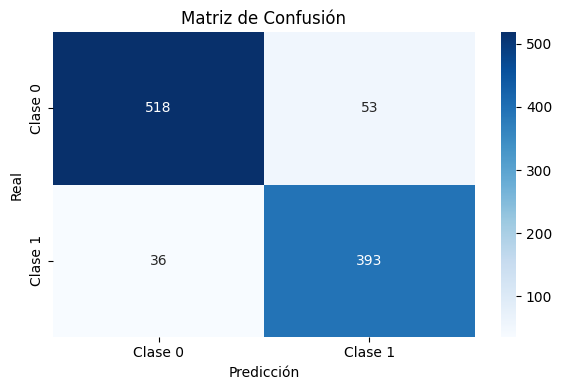

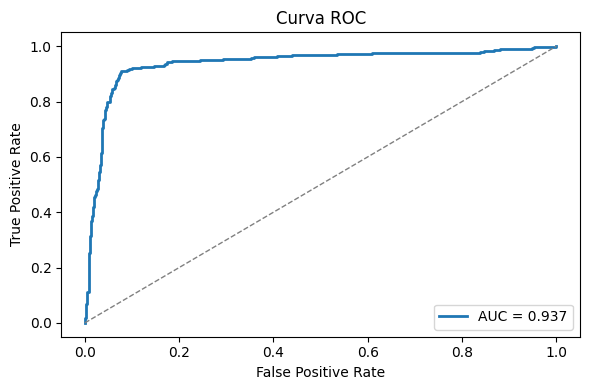

In [37]:
# Base model
logreg_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(random_state=42))
])

# Hyperparameters
param_grid = {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],  
    'model__penalty': ['l2'],                     
    'model__solver': ['liblinear', 'lbfgs', 'saga'],  
    'model__max_iter': [1000, 5000, 10000],       
    'model__tol': [1e-4, 1e-3, 1e-2],             
    'model__class_weight': [None, 'balanced']     
}

# Grid Search with cross-validation
grid_search_logreg = GridSearchCV(logreg_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_logreg.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_logreg, X_test, y_test, positive_label=1)

## 4.2 K-Nearest Neighbors

Best hyperparameter combination:
model__algorithm: auto
model__leaf_size: 10
model__metric: manhattan
model__n_neighbors: 25
model__p: 1
model__weights: distance

Best f1 in CV: 0.8333

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.85      0.88       571
           1       0.81      0.90      0.85       429

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000

              precision    recall  f1-score   support

           0       0.92      0.85      0.88       571
           1       0.81      0.90      0.85       429

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000

Accuracy : 0.868
F1-score : 0.854
Recall   : 0.897
Precision: 0.814
ROC AUC  : 0.926



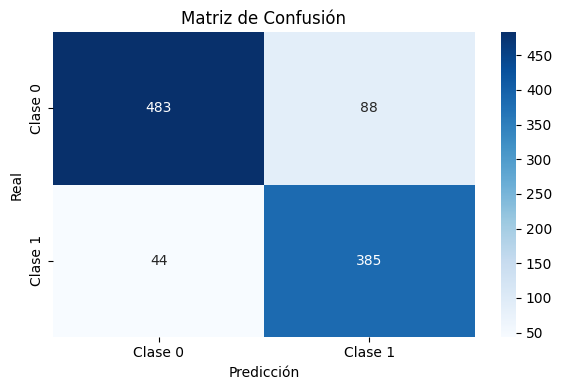

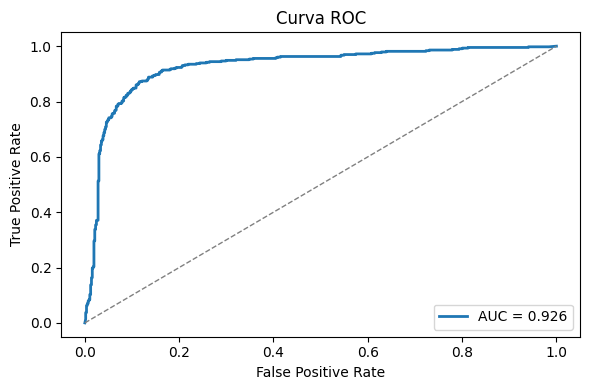

In [24]:
# Base model
knn_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', KNeighborsClassifier())
])

# Hyperparameters to try
param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 25],  
    'model__weights': ['uniform', 'distance'],      
    'model__metric': ['euclidean', 'manhattan', 'minkowski', 'chebyshev'],  
    'model__p': [1, 2],                             
    'model__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],  
    'model__leaf_size': [10, 20, 30, 40],                               
}

# Hyperparameter search
grid_search_knn = GridSearchCV(knn_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_knn.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_knn, X_test, y_test, positive_label=1)

## 4.3 DecisionTreeClassifier

Best hyperparameter combination:
model__criterion: entropy
model__max_depth: 10
model__max_features: None
model__min_samples_leaf: 1
model__min_samples_split: 2

Best f1 in CV: 0.8462

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.89      0.90       571
           1       0.85      0.87      0.86       429

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000

              precision    recall  f1-score   support

           0       0.90      0.89      0.90       571
           1       0.85      0.87      0.86       429

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000

Accuracy : 0.882
F1-score : 0.864
Recall   : 0.874
Precision: 0.854
ROC AUC  : 0.872



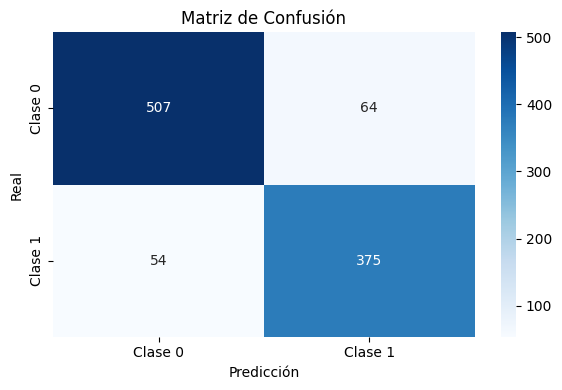

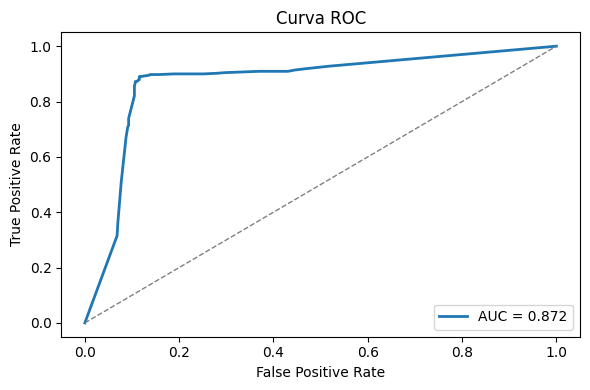

In [ ]:
# Base model
tree_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

# Hyperparameter search
param_grid = {
    'model__max_depth': [5, 10, 15, None],         
    'model__min_samples_split': [2, 5, 10],        
    'model__min_samples_leaf': [1, 2, 4],          
    'model__criterion': ['gini', 'entropy'],       
    'model__max_features': [None, 'sqrt']          
}


grid_search_tree = GridSearchCV(tree_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_tree.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_tree, X_test, y_test, positive_label=1)

## 4.4 Support Vector Classification

Best hyperparameter combination:
model__C: 10
model__gamma: 0.1
model__kernel: rbf
model__probability: True

Best f1 in CV: 0.8633

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       571
           1       0.89      0.89      0.89       429

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000

              precision    recall  f1-score   support

           0       0.91      0.91      0.91       571
           1       0.89      0.89      0.89       429

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000

Accuracy : 0.902
F1-score : 0.886
Recall   : 0.886
Precision: 0.886
ROC AUC  : 0.935



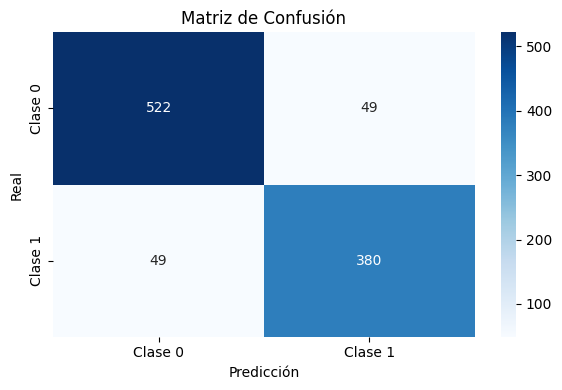

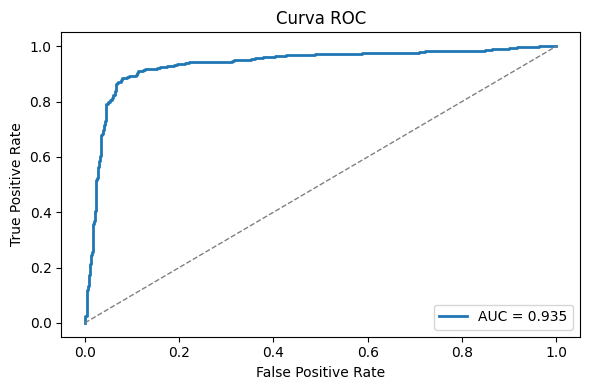

In [ ]:
# Pipeline with SVC
svm_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', SVC(random_state=42))
])

# Hyperparameters to search
param_grid = {
    'model__C': [0.1, 1, 10],                 
    'model__kernel': ['linear', 'rbf'],       
    'model__gamma': ['scale', 0.01, 0.1],     
    'model__probability': [True]              
}

# Grid Search
grid_search_svm = GridSearchCV(svm_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_svm.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_svm, X_test, y_test, positive_label=1)

## 4.5 Random Forest Classifier

Best hyperparameter combination:
model__bootstrap: True
model__max_depth: 10
model__max_features: sqrt
model__min_samples_leaf: 1
model__min_samples_split: 2
model__n_estimators: 300

Best f1 in CV: 0.8791

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       571
           1       0.91      0.90      0.90       429

    accuracy                           0.92      1000
   macro avg       0.92      0.91      0.92      1000
weighted avg       0.92      0.92      0.92      1000

              precision    recall  f1-score   support

           0       0.93      0.93      0.93       571
           1       0.91      0.90      0.90       429

    accuracy                           0.92      1000
   macro avg       0.92      0.91      0.92      1000
weighted avg       0.92      0.92      0.92      1000

Accuracy : 0.917
F1-score : 0.903
Recall   : 0.900
Precision: 0.906
ROC AUC  : 0.933



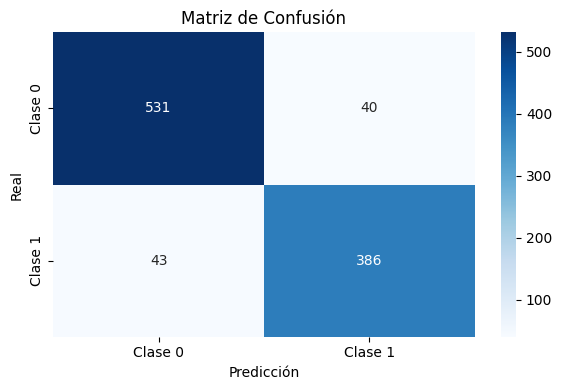

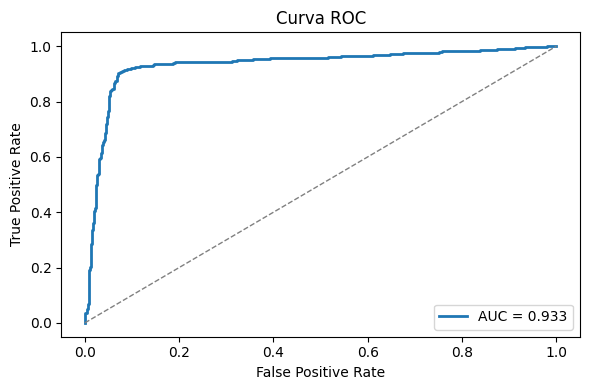

In [ ]:
# Pipeline with RandomForest
rf_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

# Hyperparameters to try
param_grid = {
    'model__n_estimators': [100, 300],             
    'model__max_depth': [10, 20, None],            
    'model__min_samples_split': [2, 5],            
    'model__min_samples_leaf': [1, 2],             
    'model__max_features': ['sqrt', 'log2'],       
    'model__bootstrap': [True]                     
}

# Grid Search
grid_search_rf = GridSearchCV(rf_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_rf, X_test, y_test, positive_label=1)

## 4.6 XGBClassifier

Best hyperparameter combination:
model__colsample_bytree: 1.0
model__gamma: 0
model__learning_rate: 0.05
model__max_depth: 7
model__min_child_weight: 1
model__n_estimators: 100
model__subsample: 0.8

Best f1 in CV: 0.8797

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.93       571
           1       0.91      0.89      0.90       429

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000

              precision    recall  f1-score   support

           0       0.92      0.93      0.93       571
           1       0.91      0.89      0.90       429

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000

Accuracy : 0.914
F1-score : 0.899
Recall   : 0.893
Precision: 0.905
ROC AUC  : 0.932



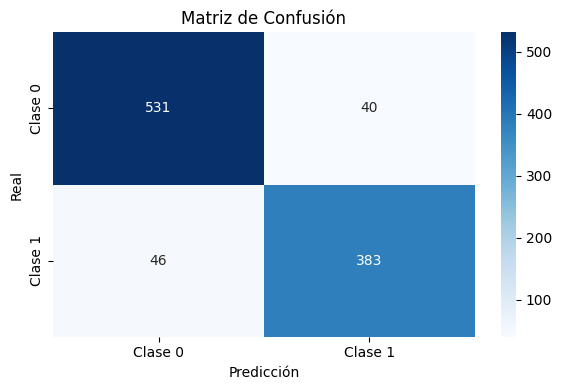

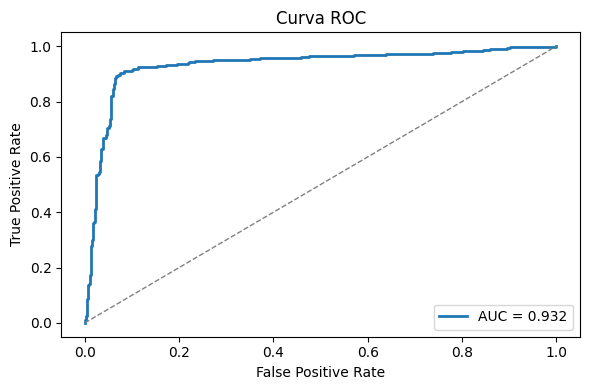

In [ ]:
# Pipeline
xgb_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', XGBClassifier(random_state=42))
])


param_grid = {
    'model__n_estimators': [100, 300],           
    'model__max_depth': [3, 7],                  
    'model__learning_rate': [0.05, 0.1],         
    'model__subsample': [0.8, 1.0],              
    'model__colsample_bytree': [0.8, 1.0],       
    'model__gamma': [0, 0.5],                    
    'model__min_child_weight': [1, 5]           
}

# Grid Search
grid_search_xgb = GridSearchCV(xgb_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_xgb, X_test, y_test, positive_label=1)

## 4.7 CatBoostClassifier

0:	learn: 0.6537844	total: 158ms	remaining: 31.4s
1:	learn: 0.6194564	total: 161ms	remaining: 16s
2:	learn: 0.5866652	total: 166ms	remaining: 10.9s
3:	learn: 0.5595735	total: 169ms	remaining: 8.29s
4:	learn: 0.5360696	total: 172ms	remaining: 6.72s
5:	learn: 0.5133922	total: 174ms	remaining: 5.64s
6:	learn: 0.4955711	total: 176ms	remaining: 4.86s
7:	learn: 0.4763183	total: 178ms	remaining: 4.27s
8:	learn: 0.4624699	total: 180ms	remaining: 3.82s
9:	learn: 0.4467594	total: 182ms	remaining: 3.45s
10:	learn: 0.4331074	total: 183ms	remaining: 3.15s
11:	learn: 0.4212423	total: 185ms	remaining: 2.9s
12:	learn: 0.4125289	total: 187ms	remaining: 2.7s
13:	learn: 0.4024369	total: 189ms	remaining: 2.51s
14:	learn: 0.3930545	total: 193ms	remaining: 2.38s
15:	learn: 0.3867103	total: 194ms	remaining: 2.23s
16:	learn: 0.3791273	total: 196ms	remaining: 2.11s
17:	learn: 0.3738307	total: 198ms	remaining: 2.01s
18:	learn: 0.3677762	total: 200ms	remaining: 1.91s
19:	learn: 0.3618479	total: 202ms	remaining: 

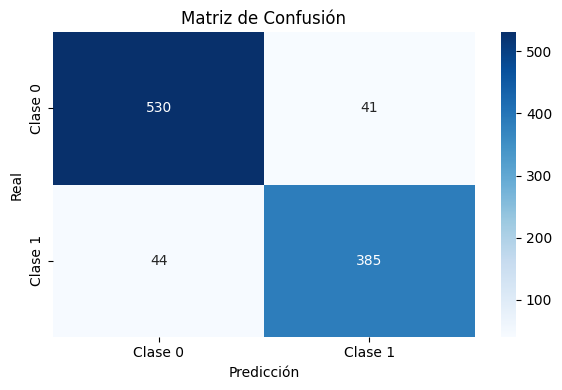

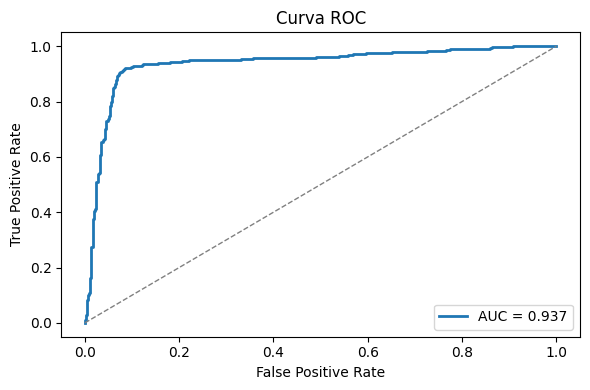

In [ ]:
cat_features_idx = [X_train.columns.get_loc(col) for col in cat_cols]

# Base model
cat_model = CatBoostClassifier(
    random_state=42,
    cat_features=cat_features_idx
)

# Hyperparameters to try
param_grid = {
    'iterations': [200, 500, 1000],      
    'depth': [6, 8, 10],                 
    'learning_rate': [0.05, 0.1, 0.2],   
    'l2_leaf_reg': [3, 5, 10],           
    'subsample': [0.8, 1.0]              
}

# Grid Search (we use the CatBoost model directly, without a pipeline)
grid_search_cat = GridSearchCV(cat_model, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_cat.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_cat, X_test, y_test, positive_label=1)

## 4.8 StackingClassifier

Best hyperparameter combination:
model__final_estimator__C: 10
model__logreg__C: 1
model__rf__max_depth: 10
model__rf__n_estimators: 100
model__svc__C: 0.1
model__svc__kernel: linear
model__xgb__learning_rate: 0.05
model__xgb__n_estimators: 300

Best f1 in CV: 0.8851

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       571
           1       0.91      0.90      0.90       429

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000

              precision    recall  f1-score   support

           0       0.93      0.93      0.93       571
           1       0.91      0.90      0.90       429

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000

Accuracy : 0.918
F1-score : 0.904
Recall   : 0.902
Pre

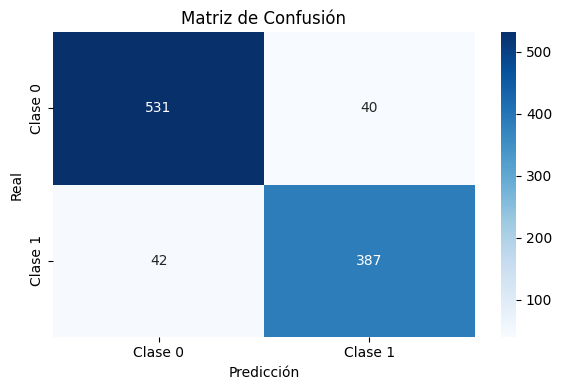

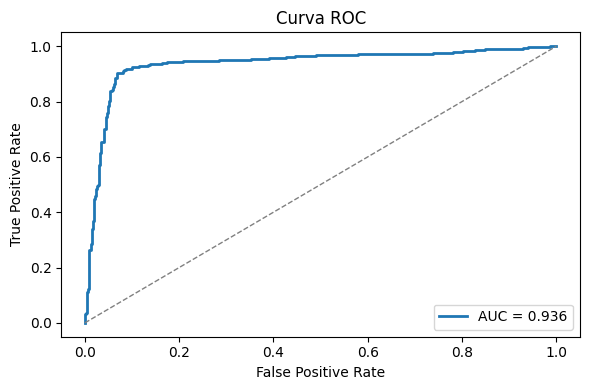

In [30]:
# Base models with additional hyperparameters
estimators = [
    ('logreg', LogisticRegression(max_iter=1000, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('xgb', XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)),
    ('svc', SVC(probability=True, random_state=42)) 
]

# StackingClassifier
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=42),
    cv=5,  
    n_jobs=-1
)

# Full pipeline
stack_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', stack_model)
])

# Hyperparameters for GridSearchCV
param_grid = {
    'model__final_estimator__C': [0.01, 0.1, 1, 10],
    
    'model__logreg__C': [0.1, 1, 10],
    
    'model__rf__n_estimators': [100, 300],
    'model__rf__max_depth': [None, 10, 20],
    
    'model__xgb__n_estimators': [100, 300],
    'model__xgb__learning_rate': [0.05, 0.1],
    
    'model__svc__C': [0.1, 1, 10],
    'model__svc__kernel': ['linear', 'rbf']
}

# Grid Search
grid_search_stack = GridSearchCV(stack_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search_stack.fit(X_train, y_train)

# Model evaluation
evaluate_classifier(grid_search_stack, X_test, y_test, positive_label=1)

Finally, after evaluating the different models presented in the previous section, the StackingClassifier model is chosen as the final approach. It stacks Logistic Regression, Random Forest, XGBoost and SVM, integrating the output of these classifiers through a final estimator, also based on logistic regression.

This model learns to combine multiple base models, allowing it to capture complementary patterns, reduce bias and learn the best combination of models. In addition, the model was trained with GridSearchCV, with a hyperparameter search over both the base models and the meta-model, ensuring a final configuration that does not depend on a single training set.

# 5. Evaluation

In [ ]:
def get_metrics(model, X_test, y_test, positive_label=1):
    if hasattr(model, "best_estimator_"):
        best = model.best_estimator_
    else:
        best = model

    y_pred = best.predict(X_test)
    if hasattr(best, "predict_proba"):
        proba = best.predict_proba(X_test)
        idx_pos = list(best.classes_).index(positive_label)
        y_score = proba[:, idx_pos]
    else:
        y_score = best.decision_function(X_test)

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, pos_label=positive_label),
        "Recall": recall_score(y_test, y_pred, pos_label=positive_label),
        "Precision": precision_score(y_test, y_pred, pos_label=positive_label),
        "ROC_AUC": roc_auc_score(y_test, y_score)
    }

In [ ]:
model_results = []
model_names = [
    ("Logistic Regression", grid_search_logreg),
    ("KNN", grid_search_knn),
    ("Decision Tree", grid_search_tree),
    ("SVM", grid_search_svm),
    ("Random Forest", grid_search_rf),
    ("XGBoost", grid_search_xgb),
    ("CatBoost", grid_search_cat),
    ("Stacking", grid_search_stack)
]

for name, model in model_names:
    metrics = get_metrics(model, X_test, y_test, positive_label=1)
    metrics["Modelo"] = name
    model_results.append(metrics)

df_results = pd.DataFrame(model_results).set_index("Modelo")
df_results

,Accuracy,F1,Recall,Precision,ROC_AUC
Modelo,,,,,
Logistic Regression,0.911,0.898286,0.916084,0.881166,0.937312
KNN,0.868,0.853659,0.897436,0.813953,0.926177
Decision Tree,0.882,0.864055,0.874126,0.854214,0.872279
SVM,0.902,0.885781,0.885781,0.885781,0.934716
Random Forest,0.917,0.902924,0.899767,0.906103,0.933307
XGBoost,0.914,0.899061,0.892774,0.905437,0.932381
CatBoost,0.915,0.900585,0.897436,0.903756,0.937096
Stacking,0.918,0.904206,0.902098,0.906323,0.936218


As seen throughout the study, the goal has been to find the model with the best performance, according to a given metric, for predicting a patient with pulmonary disease. This task is considered critical, since the model could be deployed to make decisions with real clinical consequences. A false negative is serious: failing to identify a patient at real potential risk can prevent early clinical action. For this type of pulmonary disease, early prediction is necessary in order to start preventive treatments. This type of model requires full transparency in its design and implementation. Clinical discrimination and bias could occur.